In [ ]:
import numpy as np
import pandas as pd
import re
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving news.csv to news.csv


In [ ]:
data=pd.read_csv("news.csv")

In [ ]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
print(stopwords.words('english'))

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

In [ ]:
data.shape

(6335, 4)

In [ ]:
data.head()

,id,title,text,label
0,8476,You Can Smell Hillary’s Fear,"Daniel Greenfield, a Shillman Journalism Fello...",FAKE
1,10294,Watch The Exact Moment Paul Ryan Committed Pol...,Google Pinterest Digg Linkedin Reddit Stumbleu...,FAKE
2,3608,Kerry to go to Paris in gesture of sympathy,U.S. Secretary of State John F. Kerry said Mon...,REAL
3,10142,Bernie supporters on Twitter erupt in anger ag...,"— Kaydee King (@KaydeeKing) November 9, 2016 T...",FAKE
4,875,The Battle of New York: Why This Primary Matters,It's primary day in New York and front-runners...,REAL


In [ ]:
data.isnull().sum()

,0
id,0
title,0
text,0
label,0


In [ ]:
X=data.drop(columns='label',axis=1)
Y=data['label']
print(X)
print(Y)

         id                                              title  \
0      8476                       You Can Smell Hillary’s Fear   
1     10294  Watch The Exact Moment Paul Ryan Committed Pol...   
2      3608        Kerry to go to Paris in gesture of sympathy   
3     10142  Bernie supporters on Twitter erupt in anger ag...   
4       875   The Battle of New York: Why This Primary Matters   
...     ...                                                ...   
6330   4490  State Department says it can't find emails fro...   
6331   8062  The ‘P’ in PBS Should Stand for ‘Plutocratic’ ...   
6332   8622  Anti-Trump Protesters Are Tools of the Oligarc...   
6333   4021  In Ethiopia, Obama seeks progress on peace, se...   
6334   4330  Jeb Bush Is Suddenly Attacking Trump. Here's W...   

                                                   text  
0     Daniel Greenfield, a Shillman Journalism Fello...  
1     Google Pinterest Digg Linkedin Reddit Stumbleu...  
2     U.S. Secretary of State Joh

In [ ]:
port_stem = PorterStemmer()

In [ ]:
def stemming(content):
    stemmed_content = re.sub('[^a-zA-Z]',' ',content)
    stemmed_content = stemmed_content.lower()
    stemmed_content = stemmed_content.split()
    stemmed_content = [port_stem.stem(word) for word in stemmed_content if not word in stopwords.words('english')]
    stemmed_content = ' '.join(stemmed_content)
    return stemmed_content

In [ ]:
#separating the data and label
X = data['title'].values
Y = data['label'].values

In [ ]:
# APPLY STEMMING
news_dataset = data.copy()
news_dataset['content'] = news_dataset['title'].apply(stemming)

In [ ]:
# converting the textual data to numerical data
Vectorizer = TfidfVectorizer()
Vectorizer.fit(news_dataset['content'])

X = Vectorizer.transform(news_dataset['content'])

In [ ]:
print(X)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 45882 stored elements and shape (6335, 6884)>
  Coords	Values
  (0, 2230)	0.5606827254461214
  (0, 2817)	0.31703295849951846
  (0, 5631)	0.7649346276717717
  (1, 1212)	0.3538286538491304
  (1, 2101)	0.44595444447238664
  (1, 3939)	0.3279355637571237
  (1, 4462)	0.26757273402295384
  (1, 4630)	0.24403179029804972
  (1, 4905)	0.29382045650093463
  (1, 5263)	0.29163264316148546
  (1, 5933)	0.3501812302002013
  (1, 6315)	0.13561903129801023
  (1, 6571)	0.21736822482437437
  (1, 6671)	0.27855534550881683
  (2, 2536)	0.5345737509664292
  (2, 2576)	0.3357697230253524
  (2, 3335)	0.41740393299177314
  (2, 4428)	0.37615749278439464
  (2, 6015)	0.5345737509664292
  (3, 215)	0.41916879208304547
  (3, 561)	0.2969312816565521
  (3, 1764)	0.3507454498930073
  (3, 2048)	0.4448394256850793
  (3, 5956)	0.27803614912134916
  (3, 6288)	0.3148734995784654
  :	:
  (6330, 5809)	0.3024865273895357
  (6331, 4474)	0.5790025183139886
  (6331, 4493)	0

In [ ]:
print(Y)

['FAKE' 'FAKE' 'REAL' ... 'FAKE' 'REAL' 'REAL']


In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)

In [ ]:
model = LogisticRegression()
model.fit(X_train, Y_train)

LogisticRegression()

In [ ]:
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

In [ ]:
train_accuracy = accuracy_score(Y_train, train_pred)
test_accuracy = accuracy_score(Y_test, test_pred)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

print("\nClassification Report:\n")
print(classification_report(Y_test, test_pred))

print("\nConfusion Matrix:\n")
print(confusion_matrix(Y_test, test_pred))

Training Accuracy: 0.9104183109707972
Testing Accuracy: 0.8200473559589582

Classification Report:

              precision    recall  f1-score   support

        FAKE       0.82      0.85      0.83       664
        REAL       0.83      0.79      0.81       603

    accuracy                           0.82      1267
   macro avg       0.82      0.82      0.82      1267
weighted avg       0.82      0.82      0.82      1267


Confusion Matrix:

[[564 100]
 [128 475]]


In [ ]:
X_new = X_test[3].reshape(1, -1)

prediction = model.predict(X_new)
print(prediction)

if prediction[0] == 'REAL':
    print("The news is Real")
else:
    print("The news is Fake")

['FAKE']
The news is Fake


In [ ]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [ ]:
# K-MEANS CLUSTERING

k = 6
kmeans = KMeans(n_clusters=k, random_state=42)
labels = kmeans.fit_predict(X)

data['cluster'] = labels

In [ ]:
# MAPPING

cluster_map = {
    0: "Sports",
    1: "Politics",
    2: "Entertainment",
    3: "Business",
    4: "Technology",
    5: "Other"
}

data['topic'] = data['cluster'].map(cluster_map)

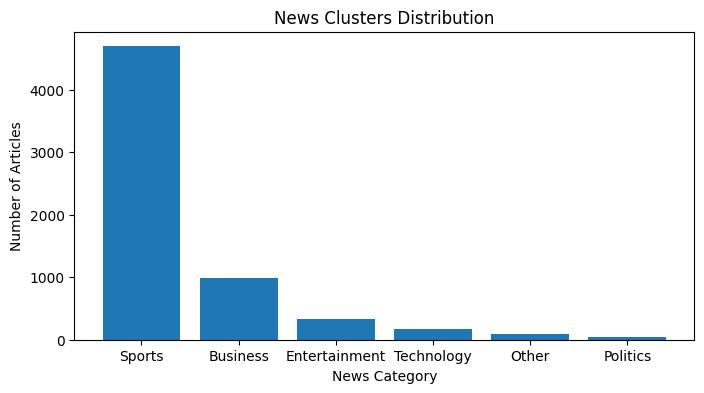

In [ ]:
topic_counts = data['topic'].value_counts()

plt.figure(figsize=(8,4))
plt.bar(topic_counts.index, topic_counts.values)

plt.title("News Clusters Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")

plt.show()


In [ ]:
# PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X.toarray())

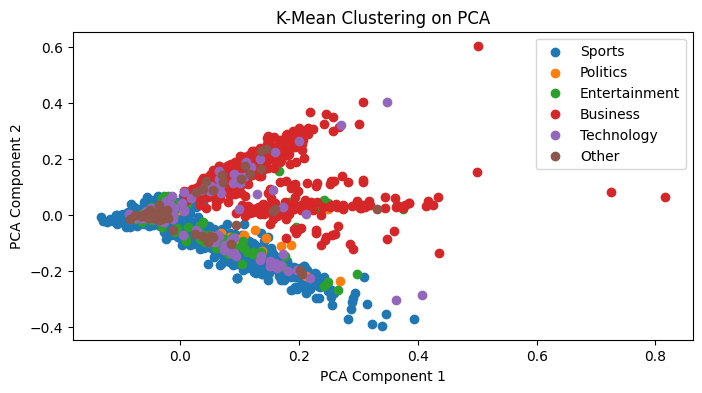

In [ ]:
# PCA VISUALIZATION

plt.figure(figsize=(8,4))

for i in range(k):
    plt.scatter(
        X_pca[labels == i, 0],
        X_pca[labels == i, 1],
        label=cluster_map[i]
    )

plt.title("K-Mean Clustering on PCA")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.show()